# CIS I — Assignment 2: Kinematic Calibration of a Cartesian Robot

This notebook walks through the calibration scenario from the handout
(Figure 1): a cartesian-base + spherical-wrist robot carrying a special
calibration marker body, observed by an optical tracker. Your job is to
**design** the scene (where the tracker and robot go, what the calibration
body's marker layout is), **collect** data under a simulated clock, and
**fit** an improved kinematic model `ImprovedFwdKins` / `ImprovedInvKins`
that beats the nominal one over the robot's work volume: the handout asks
for `||alpha|| <= 1e-3 rad` and `||epsilon|| <= 0.2 mm`, in as little
simulated time as possible — and if you cannot get there, to report the
accuracy you achieved and how you went about it.

Everything runs against `src.simulation`, a self-contained simulator playing
the role of the physical robot + tracker (the tracker and marker-body
classes are assignment 1's, imported from `assignments/assignment1`). It
injects the kinematic errors and measurement noise — your code
never sees ground truth except where explicitly noted for
**validation/reporting** in Steps 8–10.

Unlike assignment 1, your code lives in Python modules under `src/student/`
(every function there is a stub raising `NotImplementedError`), driven from
this notebook and unit-tested from `tests/`. Keep the signatures the
notebook relies on; If you want to design the functions in a different way - feel free to do that. 
But indicate that in your report.
otherwise the design is yours. Remember the assignment's
closing note: this is a design exercise — part of the job is deciding which
items of the tracker's and robot's "spec sheet" matter for your error
budget, and your report must justify those decisions.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

import numpy as np
from src import simulation, vct3, Rot, Frame
from src.simulation import clock, constants
from src.student import metrics, registration, workflow, kinematics

np.set_printoptions(precision=4, suppress=True)
clock.reset()

## Step 1: Design the scene

Specify approximate poses (as `Frame`) for the tracking camera and the robot
base, relative to the workspace, and the calibration body's marker layout
(`List[vct3]`, local coordinates). The simulator perturbs the robot's
placement the way the handout says (`||alpha_rob|| <= 0.05`,
`||epsilon_rob|| <= 5 mm`), so `F_rob_approx` is a design value, not truth.

Things to keep in mind:

- The tracker's usable volume (Figure 2) is a frustum along its **local
  +z axis**: 100–220 cm in front of the camera, widening from a 100 cm to a
  200 cm square. `trk.is_visible(points)` checks it for you.
- This handout's tracker has **no jiggle** (`sigma_Ta = sigma_Tp = 0`): the
  pose you give it is exactly where it is, so the tracker frame is a fixed
  reference and everything you measure is expressed in it. What remains is
  0.1 mm of random noise per marker reading and a small systematic field
  (`<= 0.1 mm`, slowly varying).
- The robot's end effector sits 600 mm along the base x-axis at home, and
  the linear joints travel `0..600, -300..300, 0..600` mm — so the work
  volume is a 600 mm cube spanning x ∈ [600, 1200], y ∈ [−300, 300],
  z ∈ [0, 600] in base coordinates, and the wrist (±0.75π, ±0.75π, ±π)
  swings the 75 mm calibration body around inside it. Everything must stay
  visible.
- The calibration body's layout is exact (`a*_k == a_k`) but limited to
  `||a*_k|| <= 75 mm`. Its orientation is estimated from its markers, so
  the number of markers and how far they spread set how noisy each
  orientation reading is.
- You may define and place additional marker bodies
  (`simulation.define_marker_body` / `place_marker_body`) if your design
  wants them; their layouts are only known to ±2 mm (see Step 5).

In [2]:
class Box:
    def __init__(self, low, high):
        self.low = np.array(low, dtype=float)
        self.high = np.array(high, dtype=float)
    def shift(self, d):
        return Box(self.low + d, self.high + d)
    def grow(self, m):
        return Box(self.low - m, self.high + m)
    def expand(self, low_offset, high_offset):   # move the low side by low_offset and the high side by high_offset
        return Box(self.low + low_offset, self.high + high_offset)
    def __repr__(self):
        return f"Box(low={self.low}, high={self.high}, size={self.high - self.low})"

# We place the robot base origin at the origin of our system workspace to make kinematic computations easier as that's our main focus
F_rob_approx = Frame.eye()

# We know that Fc origin can be moved 600 mm along each axis x,y,z (0, −300, 0) mm ≤ (θ1, θ2, θ3) ≤ (600, 300, 600) mm
X_MIN, X_MAX = 0, 600          # θ1 range 
Y_MIN, Y_MAX = -300, 300       # θ2 range
Z_MIN, Z_MAX = 0, 600          # θ3 range
Fc_possible_positions = Box([X_MIN, Y_MIN, Z_MIN], [X_MAX, Y_MAX, Z_MAX])

# Fw is linked to Fc by a rigidly fixed arm of 500 mm along x axis Fcw -> so we shift the edges of our box by 500 mm in +x direction
L_CW = 500                     # Fcw arm
Fw_possible_positions = Fc_possible_positions.shift([L_CW, 0, 0])

# Fee is linked to Fw by another arm of 100 mm along x axis (BUT THIS ONE can rotate about W in 3D) -> so we can grow the edges of our box by 100 mm in each direction 
L_WE = 100                     # Fwe arm 
Fc_possible_positions = Fw_possible_positions.grow(L_WE)

# Moreover, we need to account for error in robot frame so we grow this box even more in each direction by epsilon_rob=5 mm
EPS_ROB = 5                    # robot frame position error (mm)
Fee_possible_positions = Fc_possible_positions.grow(EPS_ROB)

# However, tracker doesn't see the end effector itself but the marker body on it & Marker body has max size of 75 mm so we grow our box by 75 mm each direction
MAX_DIM_SIZE_MB = 75                  # max distance of a marker from the end effector (mm)
marker_visible_positions = Fee_possible_positions.grow(MAX_DIM_SIZE_MB)   # + the markers, up to 75 mm out

# A point at distance r from the robot origin can move Approximately r * alpha_rob due to this small rotation WITH ||alpha_rob|| <= 0.05 rad
# So we need to grow our volume to account for this by using the furthest corner as a bound
ALPHA_ROB = 0.05                                 # robot frame orientation error (rad)
furthest_corner = np.maximum(abs(marker_visible_positions.low), abs(marker_visible_positions.high))
r_max = np.linalg.norm(furthest_corner)
tilt_margin = ALPHA_ROB * r_max
marker_box = marker_visible_positions.grow(tilt_margin)
center_box = (marker_box.low + marker_box.high) / 2
half_width = max(marker_box.high[1] - center_box[1], marker_box.high[2] - center_box[2])

# Moreover, the tracker's usable volume is a frustum along its local +z axis: 100–220 cm in front of the camera, widening from a 100 cm to a 200 cm square
# so we need to make sure the end effector is always placed within that volume
TRK_Z_NEAR, TRK_Z_FAR = 1000, 2200        # tracker volume: depth
TRK_HALF_NEAR, TRK_HALF_FAR = 500, 1000   # tracker volume: half width at near / far depth
# camera in front of the robot (+x side) looking back along -x; closest distance where the front face of the box still fits
d_near = max(TRK_Z_NEAR, TRK_Z_NEAR + (half_width - TRK_HALF_NEAR) * (TRK_Z_FAR - TRK_Z_NEAR) / (TRK_HALF_FAR - TRK_HALF_NEAR))
d_far = d_near + (marker_box.high[0] - marker_box.low[0])
# Camera is on +x side of robot, looking toward -x, so 
R_tracker = Rot(matrix=np.column_stack([[0, 1, 0], [0, 0, -1], [-1, 0, 0]]))   # columns: camera x, y, z
F_tracker_approx = Frame(R_tracker, vct3(marker_box.high[0] + d_near, center_box[1], center_box[2]))
print("tracker position:", F_tracker_approx.p.vec.ravel())

# tetrahedron = 4 of the 8 corners of a cube centred on the end effector (the ones with an even number of minus signs)
# a corner (±s, ±s, ±s) is s*sqrt(3) from the centre -> s = 75/sqrt(3) puts every marker at 75 mm
# (0.1 mm less, otherwise rounding gives 75.00000000000001 mm and the 75 mm check fails)
s_mb = (MAX_DIM_SIZE_MB - 0.1) / np.sqrt(3)
mbee_local_positions = [
     vct3( s_mb,  s_mb,  s_mb),
     vct3( s_mb, -s_mb, -s_mb),
     vct3(-s_mb,  s_mb, -s_mb),
     vct3(-s_mb, -s_mb,  s_mb),
] # tetrahedron
# or simply since 0 and 40 and 30 <75
# mbee_local_positions = [
#     vct3( 40,   0,   0),
#     vct3(  0,  40,   0),
#     vct3(  0,   0,  40),
#     vct3(-30, -30, -30),
# ]

tracker position: [2499.5651    0.      300.    ]


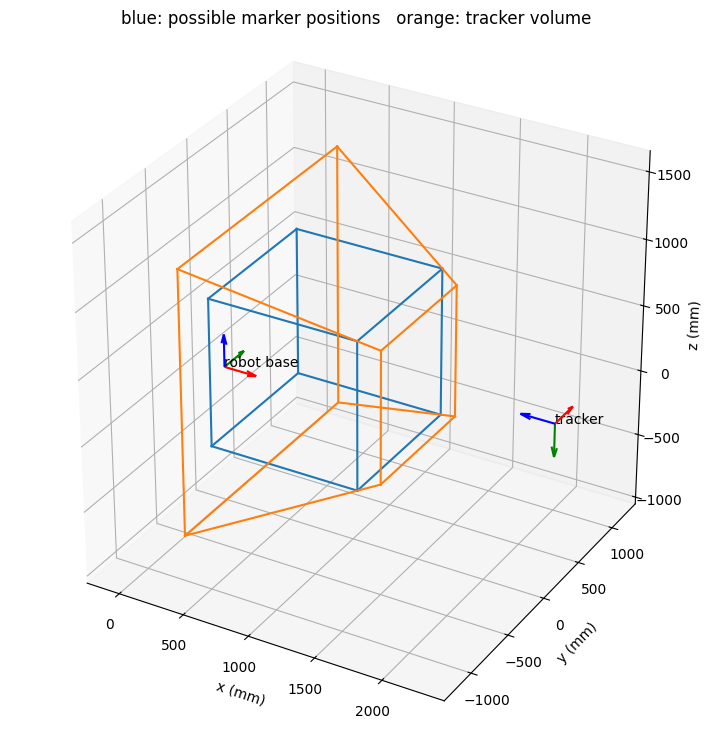

In [3]:
# drawing of the scene: robot and tracker frames, the possible positions box and the tracker volume
import itertools
import matplotlib.pyplot as plt

def draw_frame(ax, F, name, length=250):
    o = F.p.vec.ravel()
    for axis, color in zip(F.R.matrix.T, "rgb"):   # x red, y green, z blue
        ax.quiver(*o, *(length * axis), color=color)
    ax.text(*o, name)

def draw_box(ax, low, high, color):
    corners = np.array(list(itertools.product(*zip(low, high))))
    for a, b in itertools.combinations(corners, 2):
        if np.count_nonzero(a != b) == 1:          # two corners that differ in one coordinate = one edge
            ax.plot(*zip(a, b), color=color)

def draw_frustum(ax, F, color):
    square = [(1, 1), (1, -1), (-1, -1), (-1, 1)]
    near = [(F * vct3(sx * TRK_HALF_NEAR, sy * TRK_HALF_NEAR, TRK_Z_NEAR)).vec.ravel() for sx, sy in square]
    far = [(F * vct3(sx * TRK_HALF_FAR, sy * TRK_HALF_FAR, TRK_Z_FAR)).vec.ravel() for sx, sy in square]
    for i in range(4):
        ax.plot(*zip(near[i], near[i - 1]), color=color)
        ax.plot(*zip(far[i], far[i - 1]), color=color)
        ax.plot(*zip(near[i], far[i]), color=color)

ax = plt.figure(figsize=(9, 9)).add_subplot(projection="3d")
draw_frame(ax, F_rob_approx, "robot base")
draw_frame(ax, F_tracker_approx, "tracker")
draw_box(ax, marker_box.low, marker_box.high, "tab:blue")
draw_frustum(ax, F_tracker_approx, "tab:orange")
ax.set_xlabel("x (mm)"); ax.set_ylabel("y (mm)"); ax.set_zlabel("z (mm)")
ax.set_xlim(-200, 2400); ax.set_ylim(-1300, 1300); ax.set_zlim(-1000, 1600)
ax.set_box_aspect((1, 1, 1))
ax.set_title("blue: possible marker positions   orange: tracker volume")
plt.show()

## Step 2: Build the simulation

Fully provided — this wires your Step 1 choices through the simulator's
`CreateRobot` / `CreateTracker` / `CreateRobotCalibrationBody` /
`AddMarkerBodies` equivalents. The robot's hidden kinematic errors and the
tracker's hidden systematic-error field are drawn from `SEED`; your
calibration must work for *any* seed (grading uses different ones), so
don't tune to it.

`mbee_placed` is a `PlacedBody` handle pairing the calibration body with its
hidden actual placement; the body starts attached and moves with the robot.
Note that `rob.state()` already reports non-zero encoder values: the robot
starts at its physical home, `theta* = 0`, and the encoders read
`-delta_theta_sys(home) - delta_theta_rnd` there (see `rob.home_robot()`).

In [4]:
SEED = 1

rob = simulation.create_robot("rob", F_rob_approx, seed=SEED)
trk = simulation.create_tracker("trk", F_tracker_approx, seed=SEED)
mbee_placed = simulation.create_robot_calibration_body(rob, mbee_local_positions)
simulation.add_marker_bodies(trk, [mbee_placed])

print("simulation built:", rob, "|", trk.name, "| tracking", [p.body.name for p in trk.tracked_bodies])
print("robot state:", rob.state())

simulation built: Robot(name='rob', theta_cmd=[-0.0323, -0.0808, 0.0449, -0.0073, -0.0086, 0.0078]) | trk | tracking ['mBee']
robot state: RobotState(theta=array([-0.0323, -0.0808,  0.0449, -0.0073, -0.0086,  0.0078]), theta_dot=array([0., 0., 0., 0., 0., 0.]), t_elapsed=0.0, calibration_body_attached=True)


### Step 2.1: Visibility check

Before spending any simulated time, sweep a joint grid and check that
the calibration body stays inside the tracker's volume (using the *nominal*
placements — they're only tens of mm off, which is nothing against the
frustum size). If a large fraction is invisible, go back to Step 1.

In [5]:
def mbee_markers_world(theta):
    F_ee_world = rob.F_rob * rob.fwd_kins(theta)
    return [F_ee_world * a for a in mbee_local_positions]

n_vis, n_tot = 0, 0
for x in (0, 300, 600):
    for y in (-300, 0, 300):
        for z in (0, 300, 600):
            for w in (-1.8, 0.0, 1.8):
                theta = np.array([x, y, z, w, -w, w])
                n_tot += 1
                n_vis += trk.is_visible(mbee_markers_world(theta))
print(f"calibration body visible at {n_vis}/{n_tot} corner/edge poses of the work volume")

calibration body visible at 81/81 corner/edge poses of the work volume


## Step 3: Unit tests

`tests/test_simulation.py` is provided and passes as shipped — read it as
an example. `tests/test_student.py` exercises *your* `src/student` code:
the complete tests there fail with `NotImplementedError` until you
implement what they call, and the ones marked `TODO` are yours to write (you are required to write unit tests of each significant element, described in your
report together with their results). Re-run this cell as you go.

In [6]:
!{sys.executable} -m pytest ../tests -q -p no:cacheprovider

..............................s.s..Fs                                    [100%]
================================== FAILURES ===================================
______________________ test_improved_inv_kins_round_trip ______________________

    def test_improved_inv_kins_round_trip():
        rob = simulation.create_robot("rob", Frame.eye(), seed=0)
        improved = kinematics.ImprovedKinematics(rob, Frame.eye())
        improved.params = improved.initial_params() + 1e-3 * np.random.default_rng(7).normal(size=improved.params.shape)
        rng = np.random.default_rng(8)
        for _ in range(10):
            th = random_theta(rng)
            F = improved.fwd_kins(th)
            th_back = improved.inv_kins(F, seed=th)
            F_back = improved.fwd_kins(th_back)
            assert metrics.frame_error(F, F_back)[1] < 1e-6
>           assert metrics.frame_error(F, F_back)[0] < 1e-8
E           assert 2.1073424255447017e-08 < 1e-08

..\tests\test_student.py:149: AssertionError
====

## Step 4: Error metric

You have to measure the mismatch between two frames as
`dF = F_a^-1 F_b ≈ Frame(I + sk(alpha), epsilon)`. Implement
`metrics.frame_error` (returning `||alpha||`, `||epsilon||`) and
`metrics.summarize_errors`; every accuracy number below goes through them.

In [7]:
print("sanity:", metrics.frame_error(Frame.eye(), Frame(Rot('z', 0.01), vct3(1, 0, 0))))

sanity: (0.010000000000001442, 1.0)


## Step 5 (optional): Registration and marker-body refinement

> "It is possible to improve your estimate of a_m,k through a calibration
> process involving multiple observations of the marker body using the
> tracking camera and then averaging them."

The calibration body needs no refinement — `a*_k == a_k` by construction —
so this step only matters if your design places *additional* marker bodies
(their layouts are only known to ±2 mm, and the tracker registers each
body against its *current* nominal layout). You will need your own
`registration.register_points` (Arun's method — do not call the
simulator's solver) and `registration.average_frames` for Step 6 in any
case; `registration.refine_marker_body` is the optional part.

In [8]:
print("register_points sanity:", registration.register_points(
    [vct3(0, 0, 0), vct3(50, 0, 0), vct3(0, 50, 0), vct3(0, 0, 50)],
    [vct3(10, 0, 0), vct3(60, 0, 0), vct3(10, 50, 0), vct3(10, 0, 50)]).p)

register_points sanity: vct3(x=10.00, y=0.00, z=-0.00)
Internal Vector:
[[10.]
 [ 0.]
 [-0.]]


## Step 6: Home the robot, then a baseline in the tracker frame

> "`theta_encoders = HomeRobot()` will place the robot at a home position in
> which `theta*_k = 0` and return the current values read by the encoders.
> This may prove useful as part of your calibration process."

The encoders read `theta = theta* - delta_theta_rnd - delta_theta_sys`, so at
the physical home they expose the systematic offset of every joint
directly. Implement `workflow.measure_home_offsets` (average a few homings).

Then the baseline: the calibration body's coordinate system is exactly
`F_ee`, so every reading satisfies

    F_ee,j  =  F_X · FwdKins(theta_j)

for one constant unknown `F_X` (the robot base expressed in the tracker's
frame). Implement `workflow.collect_calibration_data` (robot move + one
`sample_marker_bodies` reading, storing the body's frame) and
`workflow.estimate_base_frame` (you'll want `registration.average_frames`),
then look at how well the **nominal** kinematics explain even a handful of
poses.

In [9]:
home_offsets = workflow.measure_home_offsets(rob, n_homings=5) # you can change the number of homings
print("delta_theta_sys at home (from the encoders):", home_offsets)

center = np.array([300.0, 0.0, 300.0, 0.0, 0.0, 0.0])
baseline_poses = [center] + [center + np.eye(6)[k] * v for k in range(3) for v in (-250.0, 250.0)] \
                 + [center + np.eye(6)[3] * 0.8, center + np.eye(6)[4] * 0.8, center + np.eye(6)[5] * 1.5]

baseline = workflow.collect_calibration_data(rob, trk, mbee_placed, baseline_poses, repeats=1)
F_X_baseline = workflow.estimate_base_frame(baseline, rob)
residuals = [metrics.frame_error(F_obs, F_X_baseline * rob.fwd_kins(th)) for th, F_obs in zip(baseline.thetas, baseline.frames)]
print(f"{len(baseline)} baseline samples in {baseline.t_collect:.1f}s")
print("nominal kinematics vs observations:", metrics.summarize_errors(residuals))

delta_theta_sys at home (from the encoders): [ 0.0299  0.0803 -0.0474  0.0074  0.0086 -0.0079]
10 baseline samples in 83.8s
nominal kinematics vs observations: {'n': 10, 'rms_angle': 0.00831841773810204, 'max_angle': 0.018738180650870063, 'rms_pos': 2.88594602352242, 'max_pos': 4.881046088292223}


## Step 7: Plan and collect the calibration data

> "The goal is to reach a specified accuracy within as short a time as
> possible." — `clock.elapsed` is the score's time component.

The handout suggests three routes and *strongly* urges the first:

1. **Estimate the kinematic parameters.** (a) Work out how closely spaced
   your samples along an axis must be for the accuracy you want — this
   depends on the error bounds `delta_sys^trk`, `omega_sys^trk`,
   `delta_sys^rob`, `omega_sys^rob`; (b) home the robot, then systematically
   move along/about each individual axis while taking data, returning home
   after each axis; (c) determine the angles between the axes and the
   `theta -> theta*` map (use any interpolation scheme you find feasible); (d) write the corrected
   forward and inverse kinematics; (e) report the updated parameters and,
   in debugging, compare them with ground truth; then "bottom line" test a
   sampled portion of the workspace.
2. **Map the space and interpolate** — many more, closely spaced points,
   and dense random-point testing.
3. A mix.

Design `workflow.plan_calibration_poses`: which joint vectors to visit, in
which order. Every parameter of your model must be excited (axis tilts need
travel along each axis; wrist axes, `F_we` and the wrist joints' distortion
need wrist rotations; the linear joints' distortion needs stops along each
joint), every pose must keep the calibration body visible, and the wrist
moves at only 0.1 rad/s. Joints 1–3 are kinematically decoupled from 4–6.

`plan_calibration_poses` takes the accuracy you are aiming for and must
size the plan from it: how many distinct poses, and how many readings of
each (a pose listed twice in a row is re-commanded, costing only `t_settle`
— which also re-rolls the joint repeatability noise — and re-read for
`delta_t_samp`). With 0.1 mm of marker noise on a <= 75 mm body, how many
readings does a 1e-3 rad orientation estimate need? Work it out before you
spend simulated time.

In [10]:
DESIRED_ACCURACY = constants.TARGET_ANG_ERR_RAD  # rad; the orientation target is the limiting one

poses = workflow.plan_calibration_poses(rob, trk, mbee_local_positions, desired_accuracy=DESIRED_ACCURACY)  # TODO: your design config
n_distinct = len({tuple(np.round(th, 6)) for th in poses})
print(f"plan: {len(poses)} readings over {n_distinct} distinct poses")

t0 = clock.elapsed
data = workflow.collect_calibration_data(rob, trk, mbee_placed, poses, repeats=10) #CHANGED repeats FROM 1 -> 10
print(f"{len(data)} samples collected in {data.t_collect:.1f}s; clock now {clock.elapsed:.1f}s")

F_X_nom = workflow.estimate_base_frame(data, rob)

plan: 64 readings over 55 distinct poses
64 samples collected in 429.8s; clock now 513.9s


## Step 8: Fit the improved kinematics

This is the assignment's core deliverable — implement
`kinematics.ImprovedKinematics` yourself and describe it in the report.

The handout's error model: `theta*_k = theta_k + delta_theta_k,rnd +
delta_theta_k,sys` on every joint (smooth, `||delta_theta_sys|| <=
delta_sys`, slope `<= omega_sys`), `d*_k = R(phi_k) d_k` for `k = 2..6`
(`d*_1 = d_1`), `F*_we = F_we dF_ee`, plus the base frame `F_X`. Choose a
parameter vector (the class docstring sketches one), write
`fwd_kins(theta, params)`, a residual against `data`, and a non-linear
least-squares `fit` (`scipy.optimize` is fine; so is a numerical
Jacobian). `inv_kins` is provided: it iterates on *your* `fwd_kins`.

**Questions for the report** (your `jacobian_rank_report` should help):
is every parameter identifiable from your poses? Is every parameter in the
handout's model identifiable *at all* — what happens to a component of
`phi_k` along `d_k`, to a rotation of the base about `d_1`, or to a joint
offset on joints 1–3 versus a shift of the base? (Which is why the home
offsets come from `HomeRobot()` rather than from the fit.) Which of the
handout's error terms are big enough to matter at the 0.2 mm / 1e-3 rad
level, and which are below the noise? How did that shape your
parameterization and your pose plan?

**Ground truth for debugging only**: `rob.ground_truth_parameters()`
returns the hidden kinematic parameters so you can compare your
`parameters_report()` with them, as the handout asks for debugging runs —
never use it in the calibration itself.

In [11]:
improved = kinematics.ImprovedKinematics(rob, F_X_nom, joint_offsets=home_offsets)
fit_info = improved.fit(data)
print("fit:", fit_info)

rank = improved.jacobian_rank_report(data)
print("jacobian rank:", rank["rank"], "/", rank["n_params"])

t_calibration = clock.elapsed
print(f"total simulated calibration time: {t_calibration:.1f}s (soft budget {constants.TARGET_TIME_SEC:.0f}s)")

estimated, truth = improved.parameters_report(), rob.ground_truth_parameters()   # truth: debugging only
print("estimated axis angles (deg):", estimated["axis_angles_deg"])
print("estimated joint offsets:", estimated["joint_offset"], "| true:", truth["joint_offset"])
print("estimated joint scales :", estimated["joint_scale"], "| true:", truth["joint_scale"])

# TODO: compare the rest (axes / tilts, F_we offset) -- mind the base-frame gauge
# axes and tool frame are only defined up to the base-frame gauge, so expect small differences here
print("estimated axes:\n", estimated["axis_vectors"], "\ntrue axes:\n", truth["axes"])
print("estimated F_we twist:", estimated["tool_offset"], "| true:", truth["F_we_twist"])

fit: {'Success (convergence criteria satisfied?)': True, 'Value of the cost function at the solution': 0.09844287210129908, 'Number of function evaluations done': 21, 'Verbal description of the termination reason': '`xtol` termination condition is satisfied.'}
jacobian rank: 34 / 34
total simulated calibration time: 513.9s (soft budget 900s)
estimated axis angles (deg): [[ 0.     90.0754 90.1816  0.7279 91.1378 90.4165]
 [90.0754  0.     88.3118 90.753   1.3694 88.5222]
 [90.1816 88.3118  0.     89.9357 89.1727  0.3156]
 [ 0.7279 90.753  89.9357  0.     91.8193 90.1681]
 [91.1378  1.3694 89.1727 91.8193  0.     89.3787]
 [90.4165 88.5222  0.3156 90.1681 89.3787  0.    ]]
estimated joint offsets: [ 0.0299  0.0803 -0.0474  0.0074  0.0086 -0.0079] | true: [ 0.0253  0.0697 -0.0583  0.0068  0.008  -0.0083]
estimated joint scales : [0.9997 0.9998 0.9997 1.     1.     1.    ] | true: [-0.0002 -0.0002 -0.0002 -0.      0.     -0.    ]
estimated axes:
 [[ 1.      0.      0.    ]
 [-0.0013  0.990

## Step 9: Evaluate `ImprovedFwdKins` over the work volume

**Ground truth for reporting only**: `rob.actual_ee_pose(theta)` (the
actual end-effector pose in the workspace for an encoder command `theta`)
is a hidden value you have access to here only because this notebook
doesn't gate it. Use it *only* in Steps 9–10 to compute and report your
achieved error. With no tracker jiggle, the tracker's true pose is the one
you specified, so `F_trk = trk.nominal_pose()` maps between the workspace
and the tracker frame.

The metric, per test pose `theta_i`, with `F̂_X` your estimated base frame:

    dF_i = (F_trk^-1 · F*_ee(theta_i))^-1 · (F̂_X · ImprovedFwdKins(theta_i))

Report `||alpha||` and `||epsilon||` statistics over the grid below (which
is fixed — don't change it) for the nominal kinematics and for yours, and
compare against `constants.TARGET_POS_ERR_MM` / `TARGET_ANG_ERR_RAD`.
Evaluation reads the oracle only; it must not move the robot or sample the
tracker.

In [12]:
test_levels = {0: (100.0, 300.0, 500.0), 1: (-200.0, 0.0, 200.0), 2: (100.0, 300.0, 500.0),
               3: (-1.3, 0.0, 1.3), 4: (-1.3, 0.0, 1.3), 5: (-2.0, 0.0, 2.0)}
test_grid = [np.array([x, y, z, a, b, c])
             for x in test_levels[0] for y in test_levels[1] for z in test_levels[2]
             for a in test_levels[3] for b in test_levels[4] for c in test_levels[5]]
test_grid = [th for th in test_grid if trk.is_visible(mbee_markers_world(th))]
print(f"{len(test_grid)} visible test poses")

F_trk = trk.nominal_pose()

fwd_err_nominal, fwd_err_improved = [], []
for theta in test_grid:
    #pass
    # TODO, for each test pose:
    truth = F_trk.inv() * rob.actual_ee_pose(theta)   # ground truth, reporting only
    #prediction with the nominal kinematics: F_X_nom * rob.fwd_kins(theta)
    fwd_err_nominal.append(metrics.frame_error(truth, F_X_nom * rob.fwd_kins(theta)))
    #prediction with yours: improved.predict_in_tracker(theta)
    fwd_err_improved.append(metrics.frame_error(truth, improved.predict_in_tracker(theta)))
    # appended metrics.frame_error(truth, prediction) to the two lists above

print("nominal :", metrics.summarize_errors(fwd_err_nominal))
print("improved:", metrics.summarize_errors(fwd_err_improved))

729 visible test poses
nominal : {'n': 729, 'rms_angle': 0.03257775455682396, 'max_angle': 0.05402177296186583, 'rms_pos': 7.9044782417786745, 'max_pos': 16.469521805332537}
improved: {'n': 729, 'rms_angle': 0.00020272823115595682, 'max_angle': 0.00037631710560406497, 'rms_pos': 0.06785319523497467, 'max_pos': 0.10430923608582213}


## Step 10: Evaluate `ImprovedInvKins`

For a target pose `F` (in the tracker frame), `theta =
ImprovedInvKins(F̂_X^-1 F)`, then actually move the robot there and compare
where it ends up — `mbee_placed.actual_placement` after the move, relative to
`F_trk` — with the target. Use targets you know are reachable (e.g.
ground-truth poses of test-grid joint vectors). The handout asks for the
time required for testing as well as for calibration, so keep track of it.
Note that every real move includes the joint repeatability noise
`sigma_rnd`; think about what floor that puts on this number.

In [13]:
rng = np.random.default_rng(0)
targets = [test_grid[i] for i in rng.choice(len(test_grid), size=min(40, len(test_grid)), replace=False)]
t_test_start = clock.elapsed

inv_err_nominal, inv_err_improved = [], []
for theta_t in targets:
    F_target = F_trk.inv() * rob.actual_ee_pose(theta_t)   # a reachable target, in the tracker frame
    #pass
    # TODO, for the nominal kinematics (rob, F_X_nom) and yours (improved, improved.base_frame()):
    for kins, F_X, errs in [(rob, F_X_nom, inv_err_nominal), (improved, improved.base_frame(), inv_err_improved)]:
        theta = kins.inv_kins(F_X.inv() * F_target, seed=theta_t)
        rob.move_joints(theta)
        actual = F_trk.inv() * mbee_placed.actual_placement   # ground truth, reporting only
        errs.append(metrics.frame_error(F_target, actual)) #append metrics.frame_error(F_target, actual)

t_testing = clock.elapsed - t_test_start
print("nominal :", metrics.summarize_errors(inv_err_nominal))
print("improved:", metrics.summarize_errors(inv_err_improved))

nominal : {'n': 40, 'rms_angle': 0.034482229193527954, 'max_angle': 0.053838249909328506, 'rms_pos': 8.23280674478772, 'max_pos': 14.080219763750947}
improved: {'n': 40, 'rms_angle': 0.00023585250062969245, 'max_angle': 0.00046469725323387536, 'rms_pos': 0.07375186075263938, 'max_pos': 0.10953154961063177}


## Achieved performance

Summarize: nominal vs improved, forward and inverse, against the handout's
targets (0.2 mm, 1e-3 rad), plus the simulated time spent calibrating and
testing and how the calibration time was spent (homing, number of
moves/samples). If a target is not met, say what you achieved and why —
that is an acceptable outcome per the handout. Put the same table in your
report, together with results for at least one other `SEED`.

In [14]:
# TODO: summarize fwd_err_*/inv_err_* with metrics.summarize_errors against
# constants.TARGET_POS_ERR_MM / TARGET_ANG_ERR_RAD, and report t_calibration and t_testing.
print(f"targets: {constants.TARGET_ANG_ERR_RAD} rad, {constants.TARGET_POS_ERR_MM} mm\n")
print(f"{'':18}{'rms ang':>10}{'max ang':>10}{'rms pos':>10}{'max pos':>10}  met?")
for name, errs in [("fwd nominal", fwd_err_nominal), ("fwd improved", fwd_err_improved),
                   ("inv nominal", inv_err_nominal), ("inv improved", inv_err_improved)]:
    s = metrics.summarize_errors(errs)
    met = s["max_angle"] <= constants.TARGET_ANG_ERR_RAD and s["max_pos"] <= constants.TARGET_POS_ERR_MM
    print(f"{name:18}{s['rms_angle']:10.2e}{s['max_angle']:10.2e}{s['rms_pos']:10.3f}{s['max_pos']:10.3f}  {met}")

print(f"\ncalibration time: {t_calibration:.1f}s ({len(data)} samples)")
print(f"testing time:     {t_testing:.1f}s ({len(targets)} targets x 2 moves)")

targets: 0.001 rad, 0.2 mm

                     rms ang   max ang   rms pos   max pos  met?
fwd nominal         3.26e-02  5.40e-02     7.904    16.470  False
fwd improved        2.03e-04  3.76e-04     0.068     0.104  True
inv nominal         3.45e-02  5.38e-02     8.233    14.080  False
inv improved        2.36e-04  4.65e-04     0.074     0.110  True

calibration time: 513.9s (64 samples)
testing time:     1057.9s (40 targets x 2 moves)


## Seed sweep

Reruns Steps 2–10 (improved model only) for several seeds, prints one line per seed and saves the table to `../seed_sweep.csv` for the report. Uses the Step 1 design and the same test grid as Step 9.

In [15]:
import csv

SEEDS = range(1, 11)
RUN_INVERSE = True   # Step 10 moves the robot and is slow; set False for a quick forward-only sweep
full_grid = [np.array(th) for th in itertools.product(*test_levels.values())]

def run_seed(seed):
    clock.reset()
    rob = simulation.create_robot("rob", F_rob_approx, seed=seed)
    trk = simulation.create_tracker("trk", F_tracker_approx, seed=seed)
    mbee = simulation.create_robot_calibration_body(rob, mbee_local_positions)
    simulation.add_marker_bodies(trk, [mbee])

    # calibration (Steps 6-8)
    offsets = workflow.measure_home_offsets(rob, n_homings=5)
    poses = workflow.plan_calibration_poses(rob, trk, mbee_local_positions, desired_accuracy=DESIRED_ACCURACY)
    data = workflow.collect_calibration_data(rob, trk, mbee, poses, repeats=10)
    kins = kinematics.ImprovedKinematics(rob, workflow.estimate_base_frame(data, rob), joint_offsets=offsets)
    kins.fit(data)
    t_cal = clock.elapsed

    # forward test (Step 9)
    F_trk = trk.nominal_pose()
    def visible(th):
        F_ee = rob.F_rob * rob.fwd_kins(th)
        return trk.is_visible([F_ee * a for a in mbee_local_positions])
    grid = [th for th in full_grid if visible(th)]
    fwd = metrics.summarize_errors([metrics.frame_error(F_trk.inv() * rob.actual_ee_pose(th), kins.predict_in_tracker(th))
                                    for th in grid])

    # inverse test (Step 10)
    inv_errs = []
    if RUN_INVERSE:
        rng = np.random.default_rng(0)
        for i in rng.choice(len(grid), size=min(40, len(grid)), replace=False):
            F_target = F_trk.inv() * rob.actual_ee_pose(grid[i])
            rob.move_joints(kins.inv_kins(kins.base_frame().inv() * F_target, seed=grid[i]))
            inv_errs.append(metrics.frame_error(F_target, F_trk.inv() * mbee.actual_placement))
    inv = metrics.summarize_errors(inv_errs) if inv_errs else {"max_angle": np.nan, "max_pos": np.nan}

    ok = lambda s: s["max_angle"] <= constants.TARGET_ANG_ERR_RAD and s["max_pos"] <= constants.TARGET_POS_ERR_MM
    return {"seed": seed,
            "fwd_rms_ang": fwd["rms_angle"], "fwd_max_ang": fwd["max_angle"],
            "fwd_rms_pos": fwd["rms_pos"], "fwd_max_pos": fwd["max_pos"],
            "inv_max_ang": inv["max_angle"], "inv_max_pos": inv["max_pos"],
            "t_cal": t_cal, "met": ok(fwd) and (not RUN_INVERSE or ok(inv))}

print(f"{'seed':>4}{'fwd rms ang':>13}{'fwd max ang':>13}{'fwd rms pos':>13}{'fwd max pos':>13}"
      f"{'inv max ang':>13}{'inv max pos':>13}{'t_cal':>8}  met?")
sweep = []
for seed in SEEDS:
    r = run_seed(seed)
    sweep.append(r)
    print(f"{r['seed']:>4}{r['fwd_rms_ang']:13.2e}{r['fwd_max_ang']:13.2e}{r['fwd_rms_pos']:13.3f}{r['fwd_max_pos']:13.3f}"
          f"{r['inv_max_ang']:13.2e}{r['inv_max_pos']:13.3f}{r['t_cal']:8.1f}  {r['met']}")

with open("../seed_sweep.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=sweep[0].keys())
    writer.writeheader()
    writer.writerows(sweep)
print(f"\n{sum(r['met'] for r in sweep)}/{len(sweep)} seeds met both targets; saved to ../seed_sweep.csv")

seed  fwd rms ang  fwd max ang  fwd rms pos  fwd max pos  inv max ang  inv max pos   t_cal  met?
   1     2.66e-04     3.95e-04        0.067        0.107     4.92e-04        0.103   415.2  True
   2     1.16e-04     1.82e-04        0.065        0.090     4.17e-04        0.100   415.2  True
   3     1.29e-04     2.13e-04        0.077        0.108     4.01e-04        0.109   415.2  True
   4     1.25e-04     2.26e-04        0.065        0.106     4.76e-04        0.096   415.2  True
   5     1.26e-04     2.39e-04        0.074        0.115     3.65e-04        0.114   415.2  True
   6     2.06e-04     3.70e-04        0.055        0.090     6.09e-04        0.091   415.2  True
   7     2.09e-04     3.30e-04        0.079        0.112     4.70e-04        0.119   415.2  True
   8     1.37e-04     2.09e-04        0.063        0.087     3.74e-04        0.095   415.2  True
   9     1.73e-04     2.66e-04        0.053        0.086     5.18e-04        0.085   415.2  True
  10     1.90e-04     3.30e-04